# WildfireSpreadTS — análise exploratória

Resumo da EDA em streaming (`scripts/eda.py`). **Protocolo:** o fold é fixado antes da EDA;
tudo o que envolve o alvo ou orienta decisões usa **somente os anos de treino**; validação e teste aparecem
apenas no inventário (o teste sem o canal de fogo). Decisões e limitações: `README.md`.

In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

def find_root():
    for candidate in (Path.cwd(), *Path.cwd().parents):
        if (candidate / 'reports' / 'eda_summary.json').exists():
            return candidate
    raise FileNotFoundError('Rode scripts/eda.py antes de abrir este notebook.')

ROOT = find_root()
summary = json.loads((ROOT / 'reports' / 'eda_summary.json').read_text(encoding='utf-8'))
protocol = summary['protocol']
figures = summary.get('figures', {})

def show_figure(name):
    path = figures.get(name)
    if path and (ROOT / path).exists():
        display(Image(ROOT / path))
    else:
        display(Markdown(f'_Figura `{name}` não gerada nesta execução._'))

display(Markdown(
    f"**Fold {protocol['fold']}** — treino {protocol['train_years']}, validação {protocol['validation_years']}, "
    f"teste {protocol['test_years']} · T_in = {protocol['t_in']} · gerado em {summary['generated_at_utc']} · "
    f"commit `{(summary['provenance']['repo']['commit'] or 'desconhecido')[:7]}`"
))

**Fold 2** — treino [2018, 2020], validação [2019], teste [2021] · T_in = 5 · gerado em 2026-10-02T02:44:35+00:00 · commit `2c9c36e`

## 1. Inventário (todos os anos, sem alvo)

,role,events,images,events_with_date_gaps,windows_contiguous,windows_official
2018,train,176,3773,0,2893,2893
2019,validation,74,1425,0,1055,1055
2020,train,201,4292,0,3287,3287
2021,test,156,4117,0,3337,3337


Menor imagem (H, W): 297 207 | maior imagem (pixels): 109648


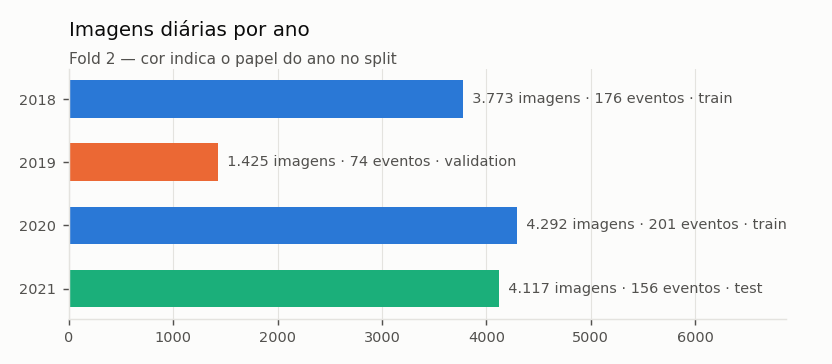

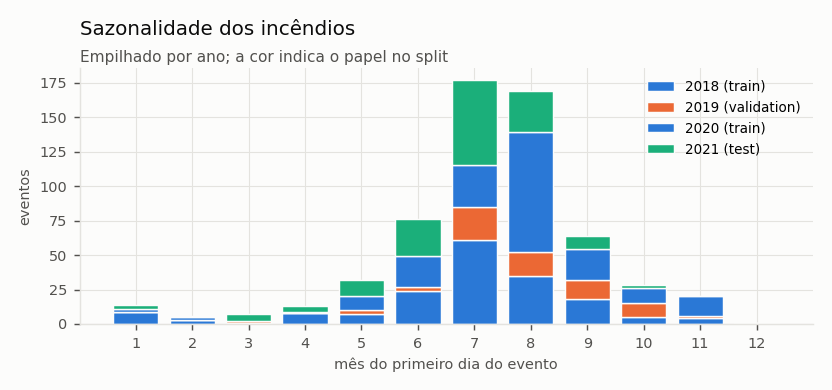

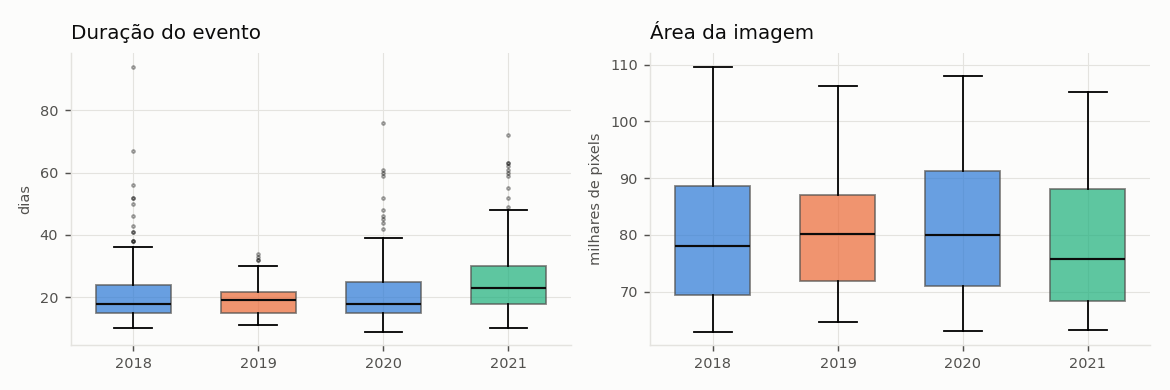

In [2]:
inventory = pd.DataFrame(summary['inventory']['per_year']).T
display(inventory[['role', 'events', 'images', 'events_with_date_gaps', 'windows_contiguous', 'windows_official']])
print('Menor imagem (H, W):', summary['inventory']['min_height'], summary['inventory']['min_width'],
      '| maior imagem (pixels):', summary['inventory']['max_pixels'])
show_figure('wsts_inventario_por_ano')
show_figure('wsts_sazonalidade')
show_figure('wsts_tamanho_eventos')

## 2. Dados faltantes, faixas físicas e médias por ano (sem alvo)

ano,2018,2019,2020,2021
canal,,,,
active_fire,0.00,0.00,0.00,NaN
aspect,0.52,1.47,1.87,0.31
elevation,0.51,1.44,1.84,0.30
energy_release_component,1.05,1.00,1.48,0.71
evi2,1.87,3.21,7.34,17.46
forecast_precipitation,0.00,0.00,0.00,0.00
forecast_specific_humidity,0.00,0.00,0.00,0.00
forecast_temperature,0.00,0.00,0.00,0.00
forecast_wind_direction,0.00,0.00,0.00,0.00


ano,2018,2019,2020,2021
canal,,,,
active_fire,0.0190,0.0060,0.0290,NaN
aspect,174.9081,174.3693,175.2359,NaN
elevation,1581.6096,1409.5344,1456.3389,NaN
energy_release_component,69.6449,64.1674,71.5580,NaN
evi2,2238.7365,2103.2260,2099.4955,NaN
forecast_precipitation,18.2758,19.0419,5.4395,NaN
forecast_specific_humidity,0.0055,0.0058,0.0052,NaN
forecast_temperature,18.2642,18.7647,18.5644,NaN
forecast_wind_direction,3.8846,14.2268,9.0108,NaN


,ano,canal,NaN (%),média,fora da faixa
5,2018,forecast_precipitation,0.000000,18.275784,354532
80,2021,pdsi,1.090454,NaN,42414


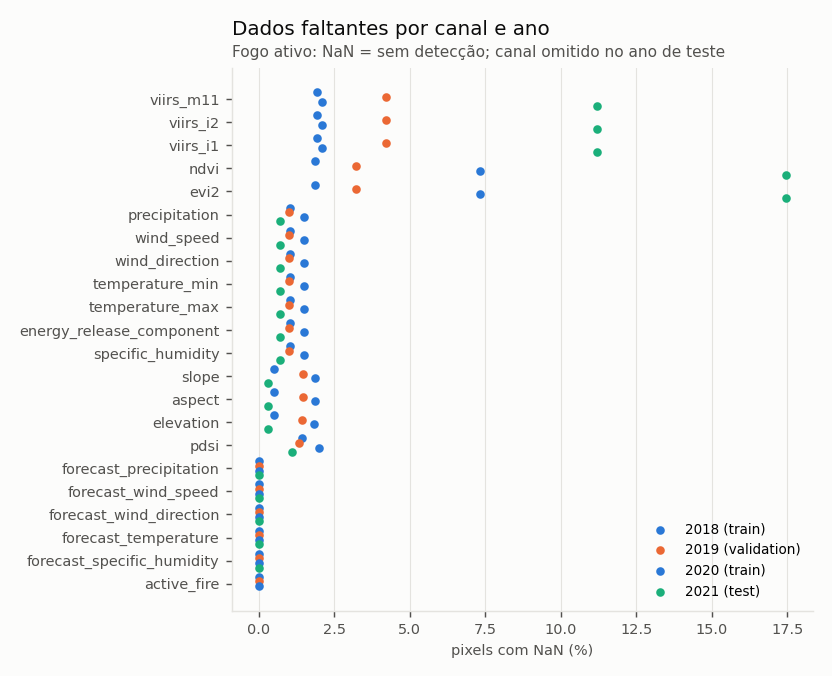

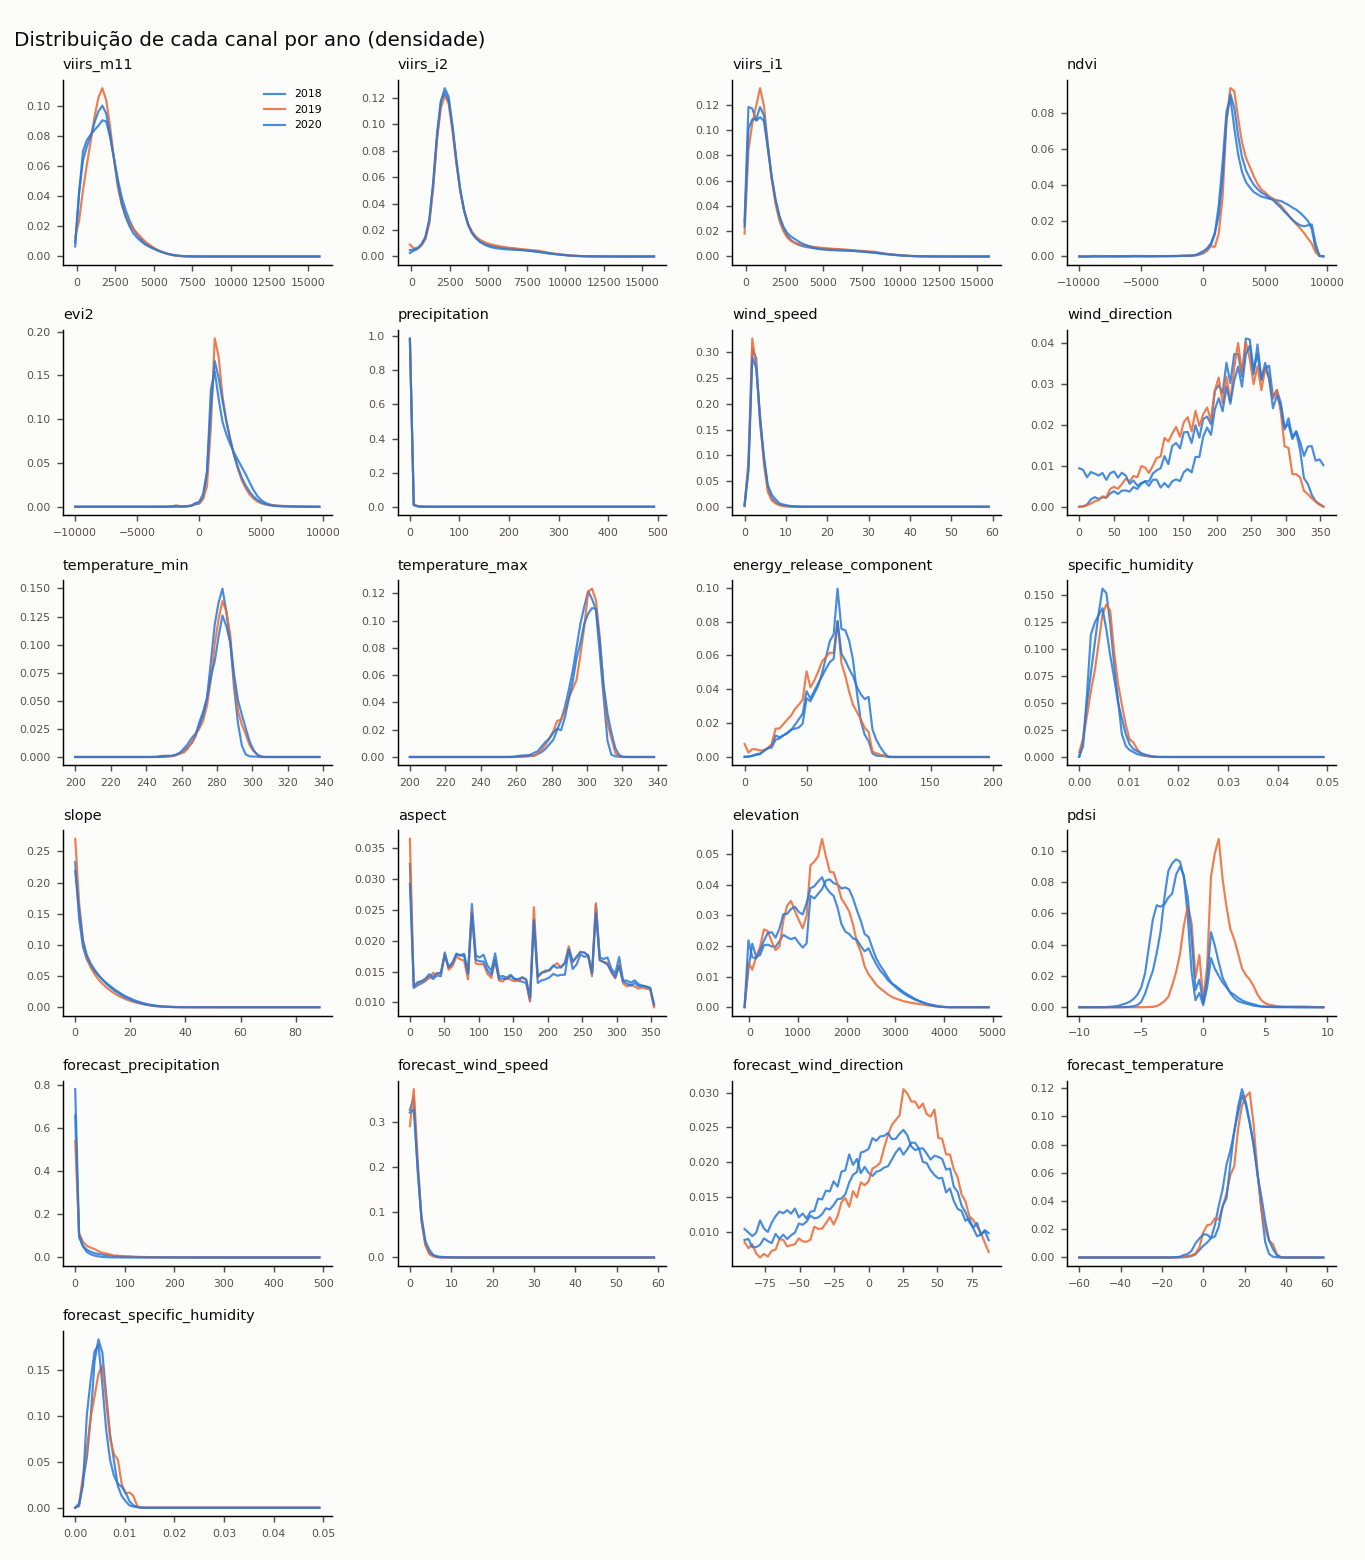

In [3]:
rows = []
for year, channels in summary['channels_by_year'].items():
    for name, entry in channels.items():
        rows.append({'ano': year, 'canal': name, 'NaN (%)': 100 * (entry['missing_rate'] or 0),
                     'média': entry.get('mean'), 'fora da faixa': entry['out_of_range']})
channels = pd.DataFrame(rows)
display(channels.pivot(index='canal', columns='ano', values='NaN (%)').round(2))
display(channels.pivot(index='canal', columns='ano', values='média').round(4))
display(channels[channels['fora da faixa'] > 0])
show_figure('wsts_faltantes_por_canal')
show_figure('wsts_histogramas_canais')

## 3. Distribuição espacial

Os três mapas abaixo respondem a perguntas diferentes:

- **Pegada dos eventos** — onde cada incêndio aconteceu e a que conjunto ele pertence. A sobreposição
  entre cores é a evidência visual de que o split por ano **não** separa regiões: 96% dos eventos de
  teste caem sobre a pegada de algum evento de treino.
- **Atividade de fogo** — quanto cada evento queimou. A contagem de pixels de fogo é o alvo, então o
  mapa exclui **toda célula de avaliação de qualquer protocolo** (o ano de teste do fold, o teste
  espacial e as três células do espaço-temporal, inclusive `só locais novos`, que é do período de
  treino); esses eventos aparecem só como localização no primeiro mapa.
- **Forçantes no espaço** — a média por evento de cada variável, que expõe o gradiente geográfico
  (elevação, secura, vento) por trás dos incêndios.

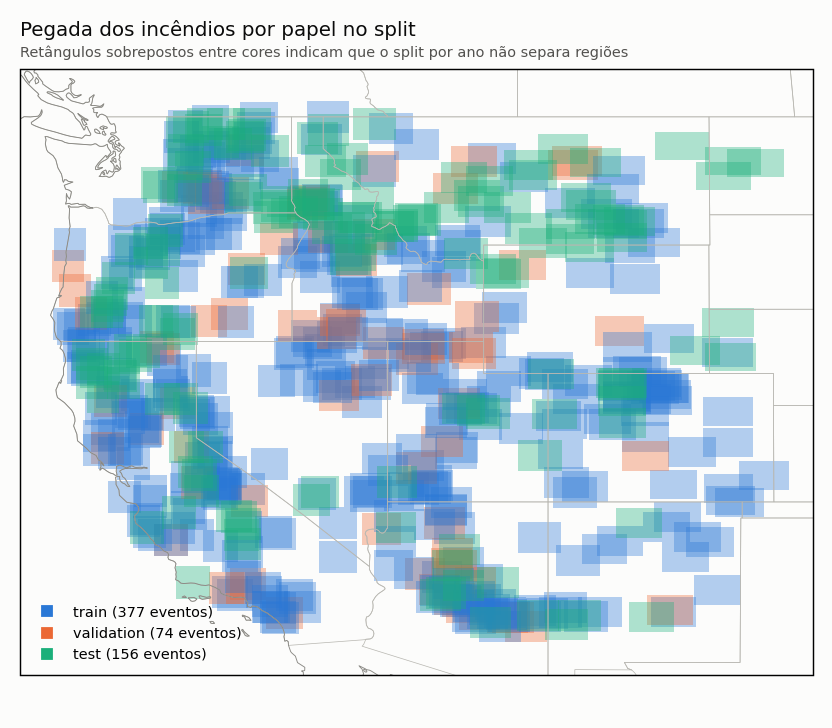

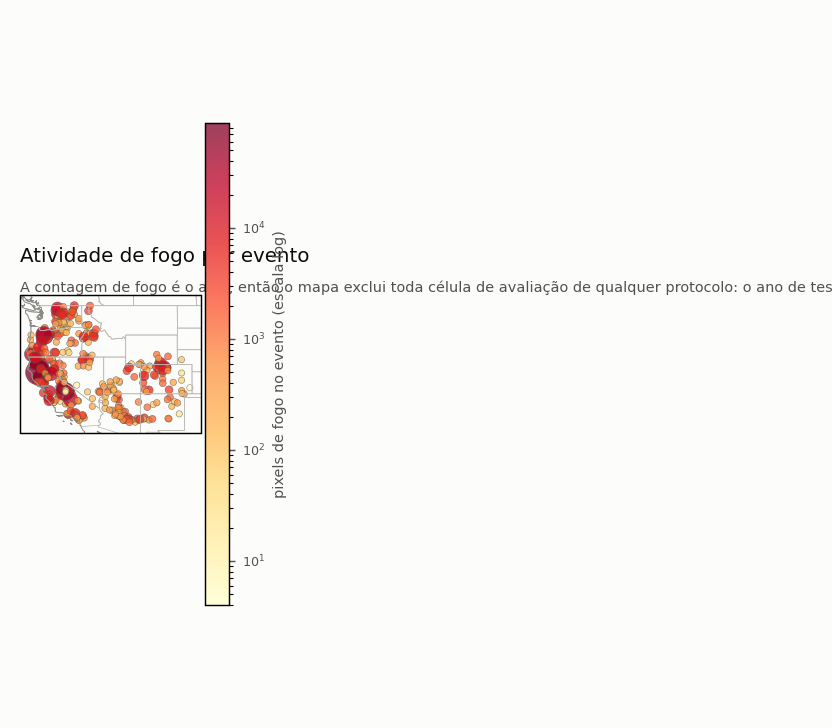

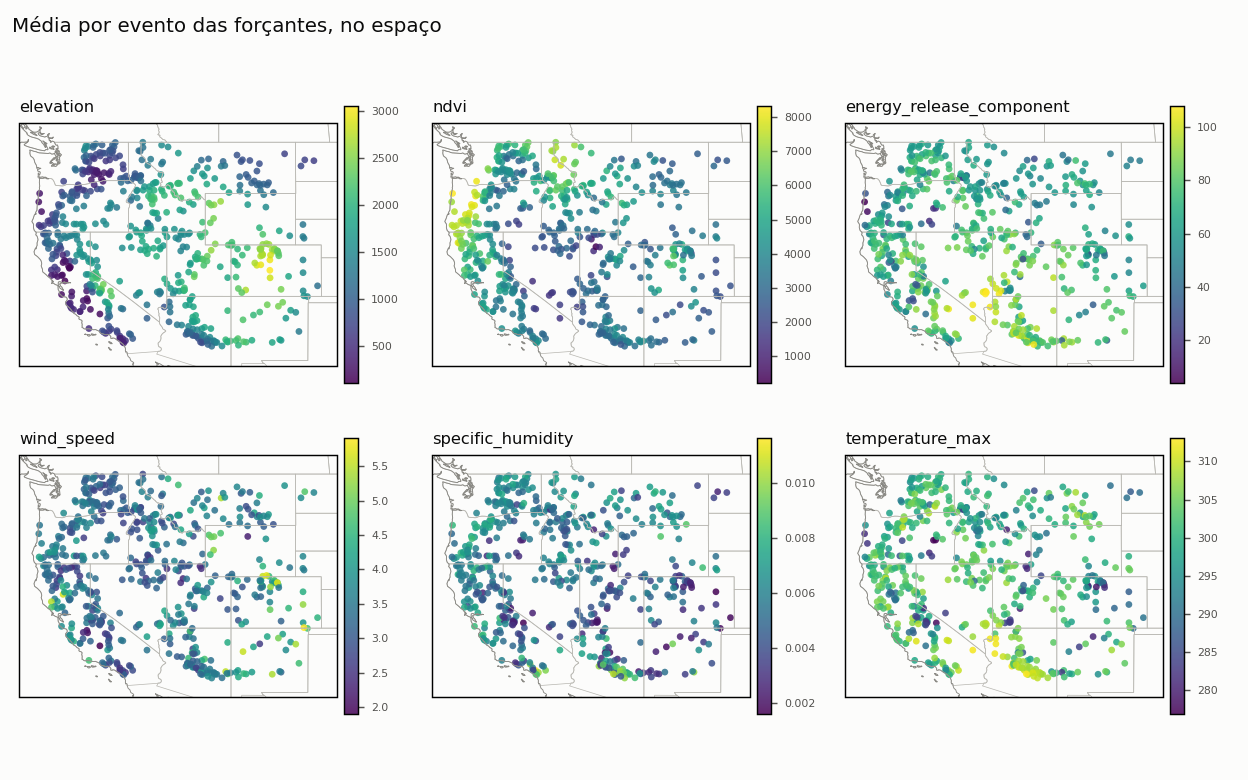

**Extremos geográficos e os 5 eventos que mais queimaram**

,lon,lat
min,-124.01,33.12
max,-102.31,48.99


,evento,papel,lon,lat,dias,fire_pixels
319,2020/fire_24332628,train,-122.980,39.913,76,88473.0
387,2020/fire_24461623,train,-119.310,37.309,48,45919.0
358,2020/fire_24332939,train,-122.146,44.807,52,35273.0
402,2020/fire_24462263,train,-122.227,45.111,35,30497.0
51,2018/fire_21889697,train,-123.833,42.411,94,26813.0


In [4]:
show_figure('wsts_mapa_eventos')
show_figure('wsts_mapa_atividade_fogo')
show_figure('wsts_mapa_variaveis')

aggregates = summary.get('event_aggregates', {})
inventory_rows = summary['inventory']['events']
if aggregates and inventory_rows and 'lon' in inventory_rows[0]:
    frame = pd.DataFrame([
        {'evento': r['key'], 'ano': r['year'], 'papel': protocol['role_by_year'][str(r['year'])],
         'lon': round(r['lon'], 3), 'lat': round(r['lat'], 3), 'dias': r['n_days'],
         **{k: v for k, v in aggregates.get(r['key'], {}).items() if k != 'n_days'}}
        for r in inventory_rows
    ])
    display(Markdown('**Extremos geográficos e os 5 eventos que mais queimaram**'))
    display(frame[['lon', 'lat']].agg(['min', 'max']).round(2))
    if frame['fire_pixels'].notna().any():
        display(frame.nlargest(5, 'fire_pixels')[
            ['evento', 'papel', 'lon', 'lat', 'dias', 'fire_pixels']])

## 4. Protocolo de split: espaço, tempo e os dois cenários

Três protocolos convivem no resumo, e cada um responde a uma pergunta diferente:

- **temporal** (fold 2, por ano) — "generaliza para um ano novo?". É o único comparável com o
  benchmark publicado, e o que **não** separa regiões: 96% dos eventos de teste caem sobre a pegada
  de algum evento de treino.
- **espacial** (blocos de 600 km, todos os anos) — diagnóstico da sobreposição e contraparte de
  volume. Não é protocolo de avaliação, porque treina com o ano de teste.
- **espaço-temporal** (bloco × ano) — o protocolo de avaliação. O teste é **lugar novo e período
  novo** ao mesmo tempo: blocos sem nenhum evento de treino, no ano mais recente.

A grade 3×3 abaixo mostra as nove células do cruzamento. Além de treino, validação e teste, duas
células são avaliadas com o **mesmo** modelo e existem para dizer de onde vem a perda:
**só futuro** (blocos de treino, ano de teste) isola o deslocamento temporal com a geografia
familiar, e **só locais novos** (blocos de teste, anos de treino) isola o deslocamento espacial
dentro do período de treino. O que a queda do teste tiver além da soma das duas é a interação entre
os deslocamentos. As quatro células restantes ficam **seladas**: usar (blocos de validação × ano de
teste) para escolher época ou limiar calibraria o modelo no período de teste.

Protocolo espaço-temporal: **fold 6** — treino [2019, 2020], validação [2018], teste [2021]; blocos de 600 km com corredor de 10 km

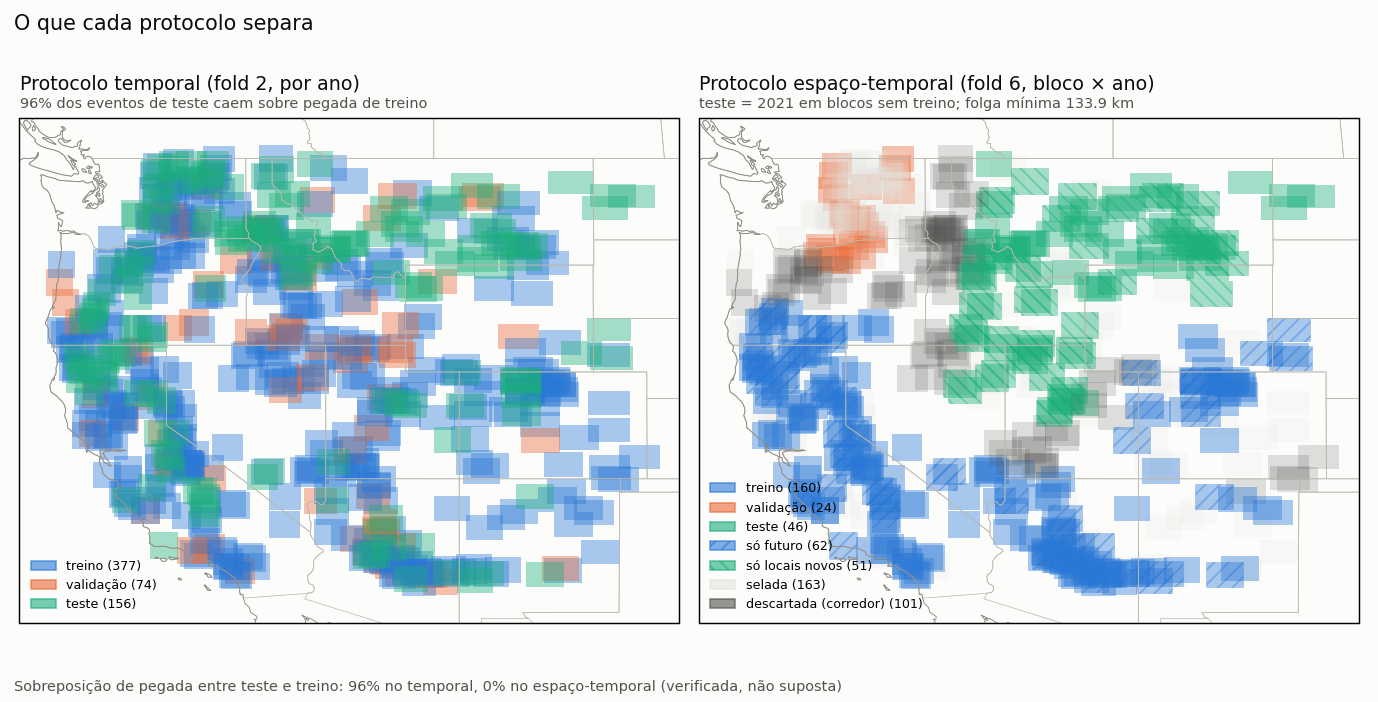

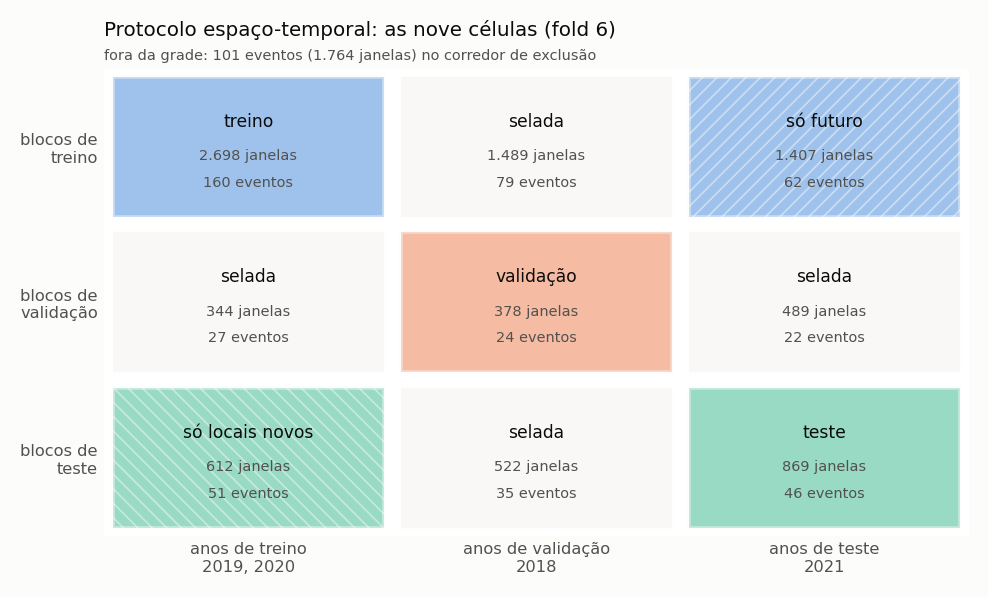

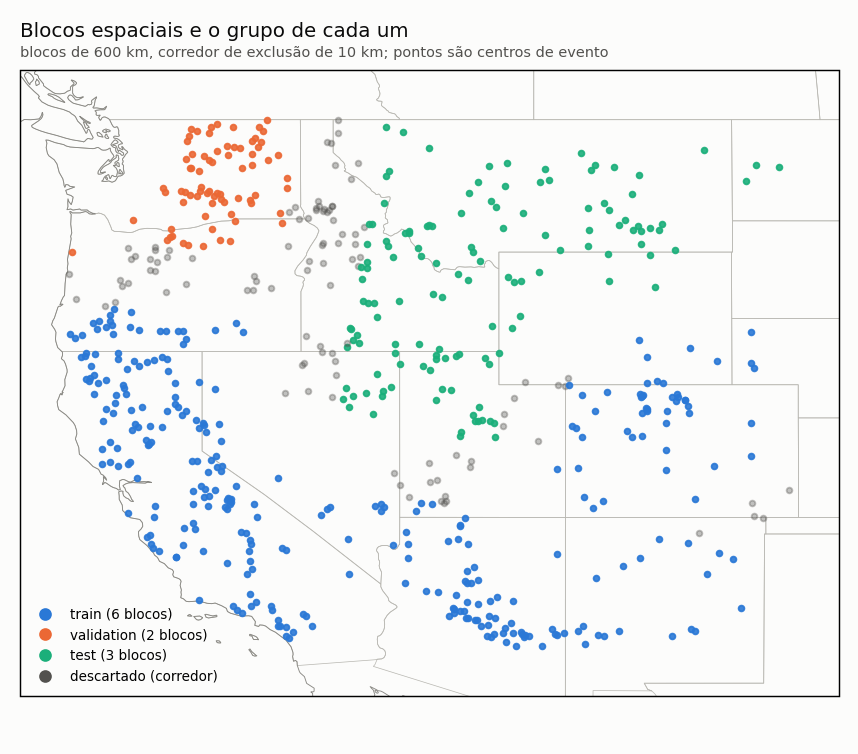

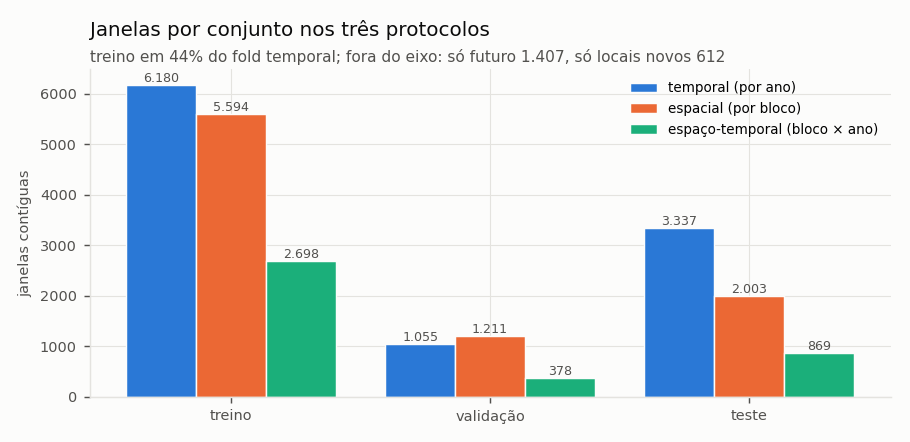

**As cinco células com papel, e o que separa cada uma do treino**

,blocos,anos,eventos,janelas,sobreposição com treino,folga mínima (km),dias após o treino
célula,,,,,,,
só futuro,train,[2021],62,1407,0.967742,0.0,47.0
só locais novos,test,"[2019, 2020]",51,612,0.000000,58.9,-527.0
teste (lugar e período novos),test,[2021],46,869,0.000000,133.9,109.0
treino,train,"[2019, 2020]",160,2698,NaN,NaN,NaN
validação,validation,[2018],24,378,0.000000,109.9,-910.0


**Volume de treino por protocolo** (uma queda de desempenho com menos dados não é evidência de pior generalização)

,temporal,spatial,spatiotemporal
janelas de treino,6180,5594,2698
anos de treino,"[2018, 2020]","[2018, 2019, 2020, 2021]","[2019, 2020]"
sobreposição teste×treino,0.961538,0.0,0.0
isola,"tempo (anos disjuntos, regiões compartilhadas)","espaço (regiões disjuntas, anos compartilhados)",espaço e tempo (bloco × ano; o teste é lugar n...


**Gate de viabilidade das células** (fixado antes de olhar qualquer rótulo)

,events,windows,passes
test,46,869,True
validation,24,378,True


Folds viáveis sob o cruzamento: [1, 6, 7, 8] · escolhido: 6
Selado (sem papel): 2844 janelas · descartado no corredor: 1764 janelas


In [5]:
comparison = summary['split_comparison']
st = summary['spatiotemporal_split']
display(Markdown(
    f"Protocolo espaço-temporal: **fold {st['fold']}** — treino {st['years']['train']}, "
    f"validação {st['years']['validation']}, teste {st['years']['test']}; blocos de "
    f"{st['parameters']['block_m'] / 1000:.0f} km com corredor de "
    f"{st['parameters']['buffer_m'] / 1000:.0f} km"
))
show_figure('wsts_mapa_splits')
show_figure('wsts_grade_espacotemporal')
show_figure('wsts_mapa_blocos_espaciais')
show_figure('wsts_janelas_por_split')

rotulos = {'train': 'treino', 'validation': 'validação', 'test': 'teste (lugar e período novos)',
           'future_only': 'só futuro', 'space_only': 'só locais novos'}
cells = pd.DataFrame([
    {'célula': rotulos[name],
     'blocos': spec['blocks'], 'anos': spec['years'],
     'eventos': spec['events'], 'janelas': spec['windows'],
     'sobreposição com treino': (st['verification'].get(name) or {}).get(
         'share_with_any_overlap_of_train'),
     'folga mínima (km)': (st['verification'].get(name) or {}).get('min_gap_to_train_km'),
     'dias após o treino': (st['verification'].get(name) or {}).get(
         'days_from_last_train_day_to_first_day')}
    for name, spec in st['cells'].items()
])
display(Markdown('**As cinco células com papel, e o que separa cada uma do treino**'))
display(cells.set_index('célula'))

display(Markdown('**Volume de treino por protocolo** (uma queda de desempenho com menos dados não '
                 'é evidência de pior generalização)'))
display(pd.DataFrame({
    kind: {'janelas de treino': comparison[kind]['train']['windows_contiguous'],
           'anos de treino': comparison[kind]['train']['years'],
           'sobreposição teste×treino': comparison['test_overlap_with_train'][kind],
           'isola': comparison['isolates'][kind]}
    for kind in ('temporal', 'spatial', 'spatiotemporal')
}))

viability = st['viability']
display(Markdown('**Gate de viabilidade das células** (fixado antes de olhar qualquer rótulo)'))
display(pd.DataFrame(viability).T[['events', 'windows', 'passes']])
folds = st.get('fold_choice') or {}
if folds:
    print('Folds viáveis sob o cruzamento:', folds.get('viable_folds'),
          '· escolhido:', folds.get('chosen'))
print('Selado (sem papel):', st['sealed']['windows_contiguous'], 'janelas ·',
      'descartado no corredor:', st['dropped']['windows_contiguous'], 'janelas')

## 5. Alvo, transições e frente (somente treino)

Prevalência de fogo em t+1, persistência (todos os pares consecutivos; não comparável à do STConv) e distância
das ignições novas ao pixel ativo mais próximo — em t e na união t−4..t (omissões do VIIRS).

Prevalência t+1: **0.00171** · pixels novos / positivos: **0.568** · dias-evento com fogo em t+1: 4700 de 7688

,persistência (treino)
f2,0.432262
fn,598147
fp,593510
note,todos os pares consecutivos; não comparável à ...
precision,0.433791
recall,0.431881
tp,454708


,max,mean,median,min,n,p25,p75
extinguishment,4691.0,127.7,43.0,0.0,4648.0,10.0,131.0
ignition,7521.0,127.3,43.0,0.0,4700.0,10.0,127.0
persistence,4853.0,97.8,21.0,0.0,4648.0,2.0,110.0


,ao fogo em t,à união da janela
"(0, 1] px",143701,197424
"(1, 2] px",71821,59342
"(2, 3] px",52973,44888
"(3, 5] px",64384,56163
"(5, 10] px",74664,66277
> 10 px,137799,142606
sem fogo na referência,52805,31447


,km até o fogo em t
max,109.457324
mean,4.558556
median,1.183973
min,0.360959
n,545342.000000
p25,0.375150
p75,3.803314


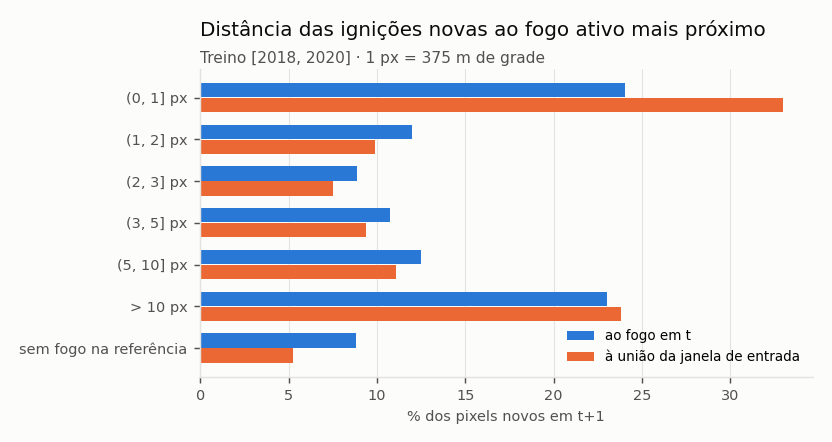

In [6]:
target = summary['train_target']
display(Markdown(
    f"Prevalência t+1: **{target['prevalence_next']:.5f}** · pixels novos / positivos: "
    f"**{target['new_fraction_of_positives']:.3f}** · dias-evento com fogo em t+1: "
    f"{target['event_days_with_fire_next']} de {target['event_days']}"
))
display(pd.Series(target['persistence_baseline_all_pairs']).to_frame('persistência (treino)'))
display(pd.DataFrame(target['transitions_per_event_day']).T.round(1))
distance = target['new_pixel_distance']
display(pd.DataFrame({'ao fogo em t': distance['to_fire_t'],
                      'à união da janela': distance['to_window_union']}))
display(pd.Series(distance['km_to_fire_t']).to_frame('km até o fogo em t'))
show_figure('wsts_distancia_ignicoes_frente')

## 6. Anel da frente (somente treino)

SMD entre pixels do anel (≤ 2 px do fogo em t) que **inflamam** em t+1 e os que não inflamam, calculada por
evento-dia e agregada por evento (IC por bootstrap de eventos). Associação descritiva, não causal; NDVI/EVI2 com
a ressalva de look-ahead do composto (seção 7). Os cossenos comparam a direção frente→candidato com o transporte
do vento e com a subida (gradiente da elevação na grade).

Fração dos pixels novos dentro do anel: 0.36031610958510196


,caveat,ci95_bootstrap_events,n_event_days,n_events,share_event_days_with_within_ring_variance,smd_mean_of_event_means
temperature_max,forçante de ~4 km reamostrada: variância quase...,"[-0.23117483723302612, -0.13092765643737334]",3355,323,0.951503,-0.181553
specific_humidity,forçante de ~4 km reamostrada: variância quase...,"[-0.17391761037175338, -0.07131614029454701]",3359,323,0.952638,-0.120977
forecast_specific_humidity,forçante de ~4 km reamostrada: variância quase...,"[-0.15154184847576493, -0.03576776769869364]",2767,292,0.784742,-0.090985
forecast_wind_speed,forçante de ~4 km reamostrada: variância quase...,"[-0.1369586139839775, -0.022988527717824673]",2767,292,0.784742,-0.082081
evi2,contaminado pelo look-ahead do composto VNP13A1,"[-0.12213662106789226, -0.04222359010759]",3355,316,0.951503,-0.079281
pdsi,forçante de ~4 km reamostrada: variância quase...,"[-0.12480249315751733, -0.02588941394562674]",3371,323,0.956041,-0.075589
temperature_min,forçante de ~4 km reamostrada: variância quase...,"[-0.10598755651519208, -0.005065928934771909]",3356,323,0.951787,-0.055767
precipitation,forçante de ~4 km reamostrada: variância quase...,"[-0.16486197176821707, 0.0596627489213423]",260,106,0.073738,-0.048309
forecast_temperature,forçante de ~4 km reamostrada: variância quase...,"[-0.09628278409031744, 0.026523387105438598]",2767,292,0.784742,-0.033915
wind_speed,forçante de ~4 km reamostrada: variância quase...,"[-0.08170517619645869, 0.01675997357719383]",3184,315,0.903006,-0.030744


,ci95_mean_bootstrap_events,conclusion,mean,median,n_events,p_value_sign_flip,p_value_sign_test,share_negative,standardized_effect
upslope_from_elevation,"[-0.036904199411653967, 0.016897632224004165]",sem efeito detectável,-0.009539,-0.017912,328,0.495701,0.246199,0.533537,-0.037582
wind_transport,"[-0.016196651896912793, 0.05248559452058753]",sem efeito detectável,0.016146,0.05261,328,0.364727,0.000032,0.384146,0.050797


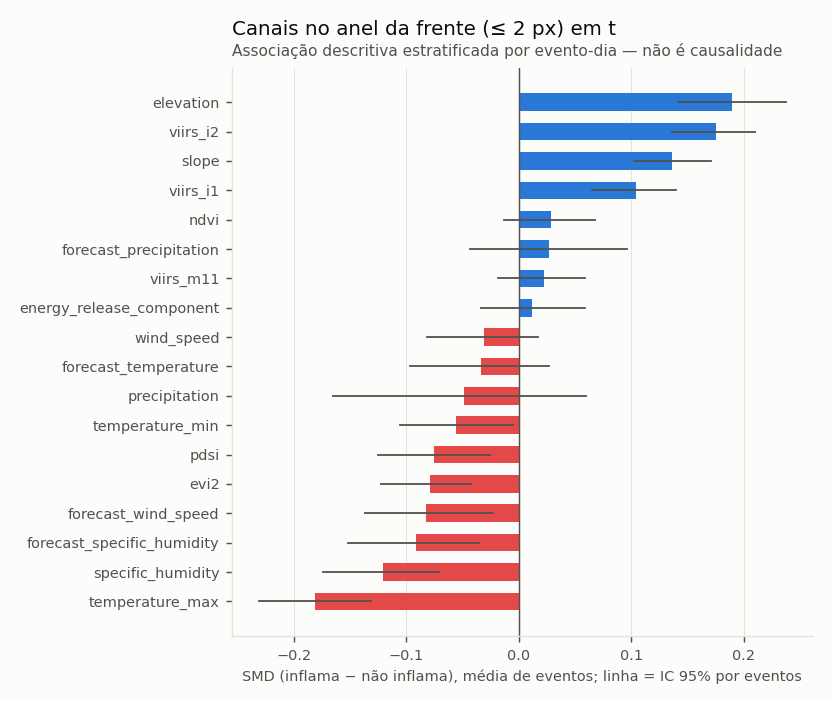

In [7]:
ring = target['front_ring']
print('Fração dos pixels novos dentro do anel:', ring['share_of_new_pixels_in_ring'])
smd = pd.DataFrame(ring['smd_ignite_vs_not_by_event_day']).T
display(smd.sort_values('smd_mean_of_event_means'))
display(pd.DataFrame(ring['cosine_front_direction_ignite_minus_not']).T)
show_figure('wsts_smd_anel_frente')

## 7. Checagens de convenção e de semântica temporal (somente treino)

**Rotação da grade EPSG:32610 (aspect × gradiente):**

,offset ~ −γ
ci95_intercept_deg,"[-0.11835598749065311, 0.016857493903275973]"
ci95_slope,"[0.8422737826936196, 0.8682495626857833]"
intercept_deg,-0.051577
slope,0.855816
slope_one_inside_ci,False


,"γ (graus), treino"
max,0.66
mean,-4.99
median,-4.73
min,-13.28
n,377.00
p25,-7.11
p75,-2.00


**Look-ahead do composto VNP13A1 (diferença-em-diferenças por evento):**

*ndvi* — cobertura 0.26896346088038886; dose-resposta -0.22859539149659983

...

**Horizonte efetivo da previsão GFS:**

*temperature* — mais perto de H1 em 100% dos bootstraps; razão de desvios GFS/GRIDMET = 0.65

,corr_observed_by_lag,profile_H0,profile_H1
0,0.564,1.000,0.451
1,0.724,0.710,0.679
2,0.757,0.316,0.793
3,0.693,0.072,0.781
4,0.532,-0.033,0.657
5,0.347,-0.053,0.466


*specific_humidity* — mais perto de H1 em 100% dos bootstraps; razão de desvios GFS/GRIDMET = 0.64

,corr_observed_by_lag,profile_H0,profile_H1
0,0.440,1.000,0.457
1,0.621,0.701,0.682
2,0.690,0.312,0.786
3,0.654,0.094,0.771
4,0.524,-0.024,0.650
5,0.362,-0.074,0.454


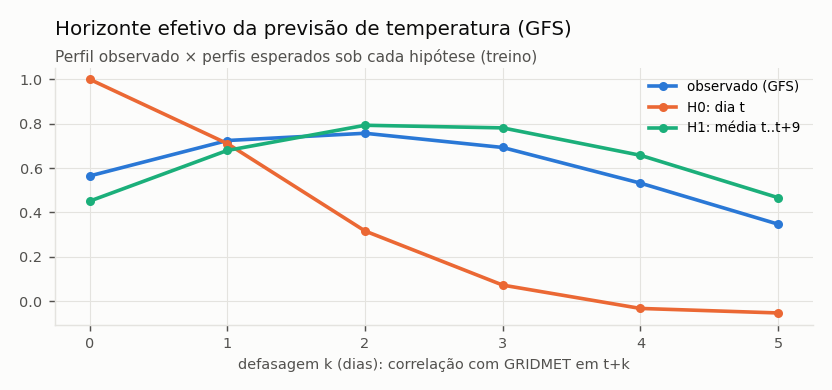

**Eixo do vento previsto × GRIDMET:** média de cos 2Δ = 0.22831344901600314

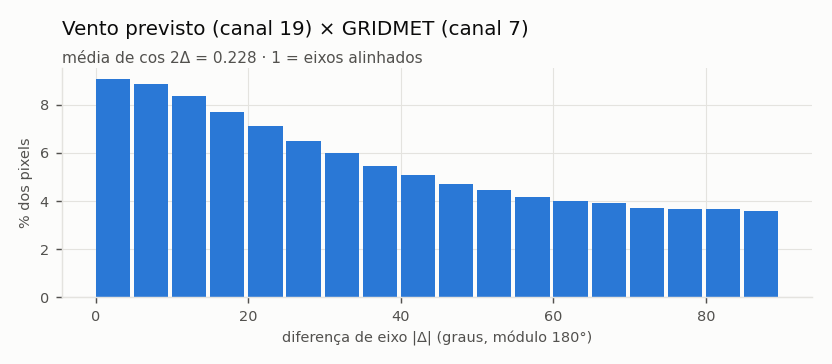

,7,8,9,10,11,18,19,20,21,22
detecções,1109,49213,190325,270323,34084,1580,46644,217084,217765,31013


In [8]:
aspect = summary['aspect_grid_rotation_check']
display(Markdown('**Rotação da grade EPSG:32610 (aspect × gradiente):**'))
display(pd.Series(aspect.get('regression_offset_on_minus_gamma', {})).to_frame('offset ~ −γ'))
display(pd.Series(summary['grid_gamma_deg_train']).to_frame('γ (graus), treino').round(2))
display(Markdown('**Look-ahead do composto VNP13A1 (diferença-em-diferenças por evento):**'))
composite = summary['composite_look_ahead_check']
for name in ('ndvi', 'evi2'):
    block = composite[name]
    display(Markdown(f"*{name}* — cobertura {block['coverage_of_burned_pixels']}; "
                     f"dose-resposta {block['dose_response_spearman_days_after_d0_vs_did']['value']}"))
    display(pd.DataFrame({'DiD': block['did'], 'placebo': block['placebo_did']}))
display(Markdown('**Horizonte efetivo da previsão GFS:**'))
for name in ('temperature', 'specific_humidity'):
    block = summary['forecast_horizon_check'].get(name, {})
    if 'corr_observed_by_lag' in block:
        display(Markdown(f"*{name}* — mais perto de H1 em {block['bootstrap_share_closer_to_H1']:.0%} dos bootstraps; "
                         f"razão de desvios GFS/GRIDMET = {block['std_ratio_gfs_over_gridmet']:.2f}"))
        display(pd.DataFrame({k: block[k] for k in ('corr_observed_by_lag', 'profile_H0', 'profile_H1')}).round(3))
show_figure('wsts_horizonte_previsao')
wind = summary['wind_axis_check']
display(Markdown(f"**Eixo do vento previsto × GRIDMET:** média de cos 2Δ = {wind['mean_cos_2delta']}"))
show_figure('wsts_convencao_vento')
hours = pd.Series(summary['active_fire_hour_histogram_utc_train'], name='detecções')
display(hours[hours > 0].to_frame().T)

## 8. Estatísticas de normalização × tabela oficial e sobreposição espacial

,mean_ours,mean_official,mean_rel_diff,std_rel_diff
elevation,1514.9369,1514.9343,0.0,0.0031
energy_release_component,70.6674,70.6675,-0.0,0.0012
evi2,2166.1516,2166.1458,0.0,0.0020
forecast_precipitation,11.4010,11.4010,0.0,0.0185
forecast_specific_humidity,0.0053,0.0053,0.0,0.0020
forecast_temperature,18.4250,18.4250,-0.0,0.0002
forecast_wind_speed,1.6449,1.6449,-0.0,0.0010
ndvi,4178.9424,4178.9683,-0.0,0.0005
pdsi,-1.6915,-1.6915,0.0,0.0083
precipitation,0.4318,0.4318,0.0,0.0000


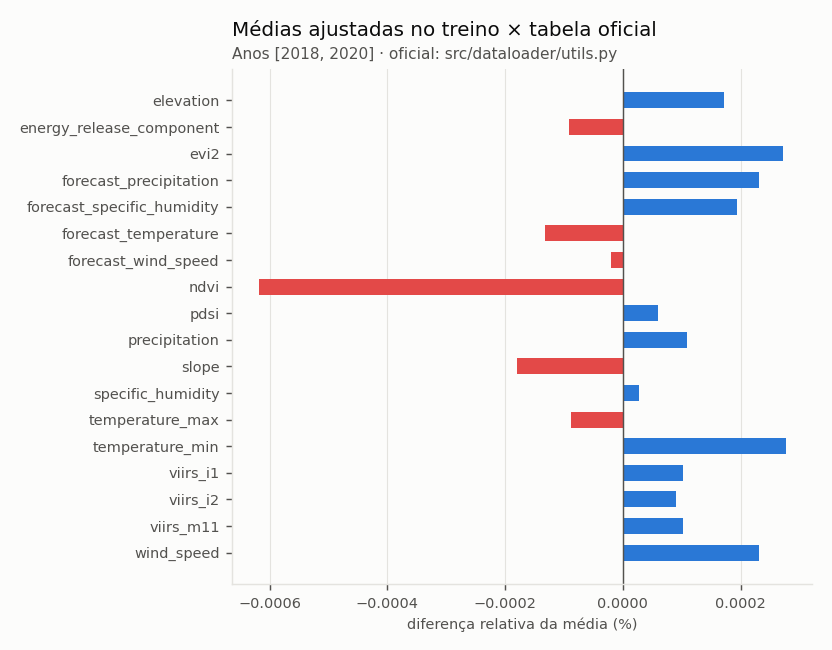

,max_overlap_fraction,n_events,note,share_overlap_gt_50pct,share_with_any_overlap
test,"{'max': 0.9633224567345386, 'mean': 0.56670417...",156,pegada = retângulo de H×W pixels de 375 m cent...,0.666667,0.961538
validation,"{'max': 0.9966887417218666, 'mean': 0.63331636...",74,pegada = retângulo de H×W pixels de 375 m cent...,0.77027,0.959459


Detecções hhmm < 100 apagadas na conversão: 0


In [9]:
official = summary.get('official_statistics_comparison')
if official:
    display(pd.DataFrame(official).T[['mean_ours', 'mean_official', 'mean_rel_diff', 'std_rel_diff']].round(4))
    show_figure('wsts_estatisticas_vs_oficial')
display(pd.DataFrame(summary['spatial_overlap_with_train']).T)
print('Detecções hhmm < 100 apagadas na conversão:', summary.get('lost_detections_hhmm_lt_100'))